# Dar_006 — P1 terrain support and quality sensitivity
**D05:** original seven SDEM region ZIPs; **D06:** existing native LOLA joins from Dar_002;
**D26:** two Kaguya DTM tiles and detached PDS3 labels.

Reuse [14 terrain feature EDA](../../../../notebooks/exploration/14_terrain_feature_eda.ipynb)
and [15 patch EDA](../../../../notebooks/exploration/15_patch_terrain_eda.ipynb) concepts:
compare terrain distributions, scale and support before environmental interpretation.

In [1]:
from pathlib import Path
import sys, json, io, re, zipfile
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p/'outline.md').is_file() and (p/'notebooks').is_dir())
sys.path[:0] = [str(ROOT/'darrel stuff/EDA'),str(ROOT)]
DATA = ROOT/'darrel stuff/data'
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from environment_workflow import LocalRun as Run, latest_completed_run
from notebooks.shared.inspection import verify_run, check_input
from research_p1_readers import (pilot_files, pin_source, read_pds4, pds4_chunks,
    pds4_definition, pds4_image, dose_profiles, pds3_number)
import research_p1_readers
def savefig(run, fig, name):
    fig.savefig(run.path(name+'.png'),dpi=140,bbox_inches='tight')
    display(fig); plt.close(fig)
def save_findings(run, findings):
    run.path('findings.json').write_text(json.dumps(findings,indent=2,default=str),encoding='utf-8')
    display(Markdown('**Executed findings**')); display(findings)
def pin(run, path): return pin_source(run, path)
def short(region): return region.split('_',2)[-1].replace('_',' ')

## Explicit bounded scope
SDEM: a central **1.2 km × 1.2 km** native 5 m patch per original region, not representative
whole-region terrain. The native image-count map is aligned with nearest-neighbor sampling;
unsupported elevations remain NaN. Compare 5 m slopes with averaged 30 m derivatives;
roughness uses 11 pixels at each scale (different physical baselines, not interchangeable).
LOLA: compare temperature associations within region/product and explicitly defined quality
bands; no new operational quality threshold is inferred. Kaguya: deterministic every-32nd
native pixel in each tile, not an averaged grid or slope estimate. The downloaded Kaguya
tiles are equatorial and do **not** overlap the polar study regions, so no false paired DEM
comparison is made.

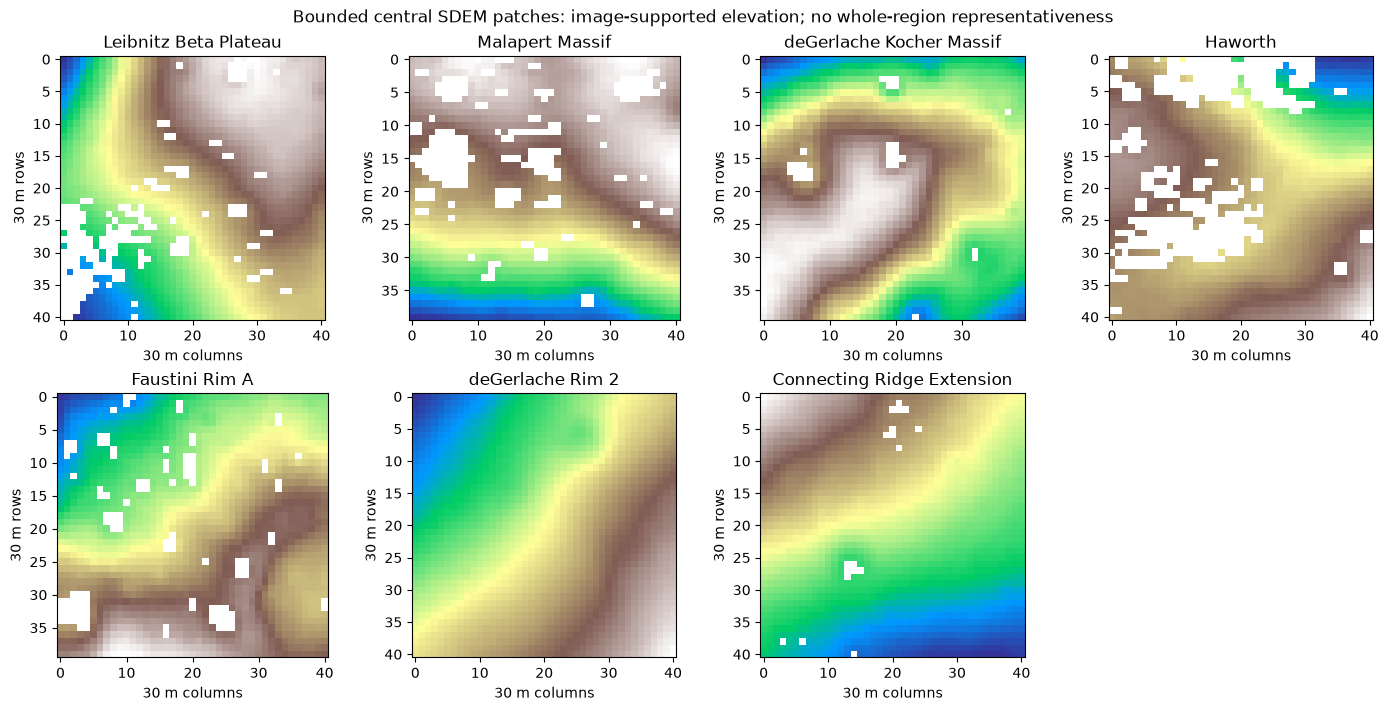

Accepted local analysis/dar_002_temperature_environment run: 20261106T082929336242Z_623f9f


rho_solar_visibility  \
quality_layer          quality_band                                         
effective_resolution_m (13.331, 17.076]                          0.728579   
                       (13.815, 18.139]                          0.614762   
                       (15.411, 19.976]                          0.490581   
                       (16.401, 21.57]                           0.630644   
                       (17.076, 93.949]                          0.804788   
                       (17.212, 22.833]                          0.557123   
                       (18.139, 99.508]                          0.479404   
                       (18.767, 24.46]                           0.781834   
                       (19.976, 98.142]                          0.458306   
                       (20.852, 29.407]                          0.475348   
                       (21.57, 85.331]                           0.629472   
                       (22.833, 123.963]                         0.570119   
                       (24.46, 149.205]                          0.790968   
                       (29.407, 193.25]                          0.446597   
                       (4.0169999999999995, 13.815]              0.665675   
                       (4.9959999999999996, 13.331]              0.672132   
                       (6.303, 15.411]                           0.485823   
                       (6.630999999999999, 16.401]               0.644285   
                       (7.0409999999999995, 17.212]              0.564020   
                       (7.194999999999999, 18.767]               0.767986   
                       (7.512, 20.852]                           0.451739   
elevation_error_m      (0.0764, 0.113]                           0.665675   
                       (0.0788, 0.11]                            0.672132   
                       (0.082, 0.121]                            0.484837   
                       (0.0828, 0.127]                           0.644285   
                       (0.0838, 0.131]                           0.564020   
                       (0.0842, 0.14]                            0.767986   
                       (0.08499999999999999, 0.162]              0.451739   
                       (0.11, 0.131]                             0.728579   
                       (0.113, 0.136]                            0.614762   
                       (0.121, 0.146]                            0.491074   
                       (0.127, 0.174]                            0.630644   
                       (0.131, 0.197]                            0.557123   
                       (0.131, 1.275]                            0.804788   
                       (0.136, 1.343]                            0.479404   
                       (0.14, 0.226]                             0.781834   
                       (0.146, 1.326]                            0.458306   
                       (0.162, 0.314]                            0.475348   
                       (0.174, 1.17]                             0.629472   
                       (0.197, 1.621]                            0.570119   
                       (0.226, 1.896]                            0.790968   
                       (0.314, 2.357]                            0.446597   
spot_count             positive                                  0.590962   
                       zero                                      0.522317   

                                                     rho_slope_deg  
quality_layer          quality_band                                 
effective_resolution_m (13.331, 17.076]                   0.211882  
                       (13.815, 18.139]                   0.380674  
                       (15.411, 19.976]                   0.529129  
                       (16.401, 21.57]                   -0.014954  
                       (17.076, 93.949]                   0.259755  
                       (17.

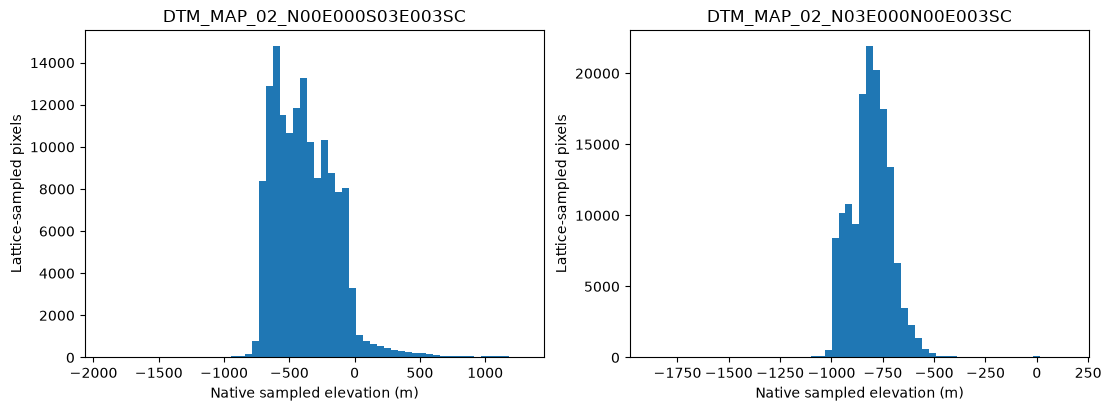

**Executed findings**

{'SDEM_regions': 7,
 'SDEM_patch_width_m': 1200,
 'quality_band_comparisons': 6109,
 'Kaguya_tiles': 2,
 'Kaguya_polar_overlap': False,
 'holds': ['SDEM central patches are not whole-region samples',
  'Unfinished LOLA slope-error excluded as in Dar_002',
  'Kaguya tiles cannot support paired polar DEM differences',
  'No geotechnical strength/passability inferred']}

Completed: C:\Darrel\Self-Projects\1 group proj\NASA-Space-Apps-Challenge-2026\darrel stuff\data\processed\analysis\dar_006_research_terrain\20261106T092901093747Z_0e1303


In [2]:
import rasterio
from rasterio.windows import Window
from rasterio.enums import Resampling
from rasterio.warp import reproject
from notebooks.shared.processing import Grid,MOON_CRS,make_grid,terrain
from moon_p1_analysis import region_footprints
REGION_LIMIT=None  # Set 1 for a representative validation run; None analyses all seven bounded patches.
regions=region_footprints(DATA)
if REGION_LIMIT is not None:
    if not isinstance(REGION_LIMIT,int) or not 1<=REGION_LIMIT<=len(regions):raise ValueError('Invalid region limit')
    regions=dict(list(regions.items())[:REGION_LIMIT])
with Run(ROOT,'analysis/dar_006_research_terrain',{'datasets':['D05','D06','D26'],'SDEM_patch_m':1200,'Kaguya_stride':32,'selected_regions':list(regions),'region_limit':REGION_LIMIT},'Moon/Terrain_And_Soil/Dar_006_research_terrain_support.ipynb') as run:
    run.input(Path(research_p1_readers.__file__))
    terrain_rows=[];images=[]
    for name,info in regions.items():
        archive=pin(run,info['archive'])
        with zipfile.ZipFile(archive) as z:
            masks=[n for n in z.namelist() if '_GLDMASK_' in n and n.lower().endswith('.tif')]
            if len(masks)!=1:raise ValueError(f'Ambiguous SDEM image-count map: {name}')
            readmes=[n for n in z.namelist() if n.endswith('README.txt')]
            if len(readmes)!=1:raise ValueError('Missing SDEM source documentation')
            run.path(f'source_readmes/{name}.txt').write_bytes(z.read(readmes[0]))
        dem_uri=f'/vsizip/{archive.as_posix()}/{info["member"]}'
        mask_uri=f'/vsizip/{archive.as_posix()}/{masks[0]}'
        with rasterio.open(dem_uri) as src:
            window=Window(src.width//2-120,src.height//2-120,240,240)
            z=src.read(1,window=window,masked=True).astype('float32').filled(np.nan)*src.scales[0]+src.offsets[0]
            transform=src.window_transform(window);bounds=rasterio.windows.bounds(window,src.transform)
            count=np.full(z.shape,np.nan,dtype='float32')
            with rasterio.open(mask_uri) as mask:
                reproject(rasterio.band(mask,1),count,src_transform=mask.transform,src_crs=mask.crs,
                    src_nodata=mask.nodata,dst_transform=transform,dst_crs=src.crs,dst_nodata=np.nan,resampling=Resampling.nearest)
            supported=np.isfinite(z)&np.isfinite(count)&(count>0)
            image_z=np.where(supported,z,np.nan)
            grid=make_grid(bounds,MOON_CRS,30)
            coarse=np.full((grid.height,grid.width),np.nan,dtype='float32');fraction=np.full_like(coarse,np.nan)
            for values,dest in [(image_z,coarse),(supported.astype('float32'),fraction)]:
                reproject(values,dest,src_transform=transform,src_crs=src.crs,src_nodata=np.nan,
                    dst_transform=grid.transform,dst_crs=grid.crs,dst_nodata=np.nan,resampling=Resampling.average)
            coarse[fraction<.99]=np.nan
        for spacing,values in [(5,image_z),(30,coarse)]:
            channels={'elevation_m':values}
            if np.isfinite(values).any():channels.update(terrain(values,spacing,11))
            for field,values in channels.items():
                finite=values[np.isfinite(values)]
                terrain_rows.append({'region':name,'spacing_m':spacing,'field':field,'patch_bounds_m':str(bounds),
                    'native_image_supported_fraction':float(supported.mean()),'finite_cells':len(finite),'total_cells':values.size,
                    'median':float(np.median(finite)) if len(finite) else np.nan,
                    'q10':float(np.quantile(finite,.1)) if len(finite) else np.nan,'q90':float(np.quantile(finite,.9)) if len(finite) else np.nan})
        images.append((name,coarse))
    terrain_table=pd.DataFrame(terrain_rows);terrain_table.to_csv(run.path('sdem_patch_scale_support.csv'),index=False)
    fig,axes=plt.subplots(2,4,figsize=(14,7),layout='constrained')
    for ax,(name,values) in zip(axes.flat,images):
        ax.imshow(values,cmap='terrain');ax.set(title=short(name),xlabel='30 m columns',ylabel='30 m rows')
    axes.flat[-1].set_visible(False);fig.suptitle('Bounded central SDEM patches: image-supported elevation; no whole-region representativeness')
    savefig(run,fig,'sdem_patch_context')
    env=latest_completed_run(ROOT,'analysis/dar_002_temperature_environment');expected=verify_run(env);run.input(env/'provenance.json')
    quality_rows=[]
    for region in regions:
        path=env/f'paired_observations/{region}.csv.gz';check_input(path,expected,{});run.input(path)
        f=pd.read_csv(path,usecols=['region','source_product','clon','clat','tbol','usable','solar_visibility','slope_deg','spot_count','effective_resolution_m','elevation_error_m'])
        centers=f[['clon','clat','spot_count','effective_resolution_m','elevation_error_m']].drop_duplicates()
        if centers.duplicated(['clon','clat']).any():raise ValueError('Ambiguous per-center quality context')
        for variable in ['spot_count','effective_resolution_m','elevation_error_m']:
            bands=centers[['clon','clat']].copy()
            if variable=='spot_count':
                bands['quality_band']=np.select([centers[variable].eq(0),centers[variable].gt(0)],['zero','positive'],default='missing')
            else:
                _,edges=pd.qcut(centers[variable].dropna(),q=3,duplicates='drop',retbins=True)
                bands['quality_band']=pd.cut(centers[variable],edges,include_lowest=True).astype(str)
            paired=f.merge(bands,on=['clon','clat'],validate='many_to_one')
            for (product,band),part in paired.loc[paired.usable].groupby(['source_product','quality_band']):
                row={'region':region,'source_product':product,'quality_layer':variable,'quality_band':band,'thermal_rows':len(part)}
                for predictor in ['solar_visibility','slope_deg']:
                    subset=part[['tbol',predictor]].dropna()
                    valid=len(subset)>=3 and subset.nunique().min()>1
                    row['rho_'+predictor]=subset.corr(method='spearman').iloc[0,1] if valid else np.nan
                    row['pairs_'+predictor]=len(subset)
                quality_rows.append(row)
    quality=pd.DataFrame(quality_rows);quality.to_csv(run.path('within_product_quality_band_correlations.csv'),index=False)
    display(quality.groupby(['quality_layer','quality_band'])[['rho_solar_visibility','rho_slope_deg']].median())
    kaguya=[];fig,axes=plt.subplots(1,2,figsize=(11,4),layout='constrained')
    for ax,path in zip(axes,pilot_files(DATA,'D26','.img')):
        label=path.with_suffix('.lbl');pin(run,path);pin(run,label);text=label.read_text(encoding='ascii')
        if 'SAMPLE_TYPE = MSB_INTEGER' not in text or 'UNIT = "METER"' not in text:raise ValueError('Unconfirmed Kaguya encoding/units')
        shape=(int(pds3_number(text,'LINES')),int(pds3_number(text,'LINE_SAMPLES')))
        raw=np.memmap(path,dtype='>i2',mode='r',shape=shape)[::32,::32].astype(float)
        valid=(raw>=pds3_number(text,'VALID_MINIMUM'))&(raw<=pds3_number(text,'VALID_MAXIMUM'))&(raw!=pds3_number(text,'DUMMY'))
        values=np.where(valid,raw*pds3_number(text,'SCALING_FACTOR')+pds3_number(text,'OFFSET'),np.nan)
        finite=values[np.isfinite(values)]
        kaguya.append({'product':path.stem,'sampled_pixels':values.size,'valid_sampled_pixels':len(finite),
            'median_elevation_m':np.median(finite),'q10_elevation_m':np.quantile(finite,.1),'q90_elevation_m':np.quantile(finite,.9),
            'lat_min':pds3_number(text,'MINIMUM_LATITUDE'),'lat_max':pds3_number(text,'MAXIMUM_LATITUDE'),
            'native_map_scale_m':pds3_number(text,'MAP_SCALE')*1000,'polar_overlap':False})
        ax.hist(finite,bins=60);ax.set(title=path.stem, xlabel='Native sampled elevation (m)',ylabel='Lattice-sampled pixels')
    savefig(run,fig,'kaguya_elevation_pilots');pd.DataFrame(kaguya).to_csv(run.path('kaguya_pilot_coverage.csv'),index=False)
    save_findings(run,{'SDEM_regions':len(regions),'SDEM_patch_width_m':1200,'quality_band_comparisons':len(quality),
        'Kaguya_tiles':len(kaguya),'Kaguya_polar_overlap':False,
        'holds':['SDEM central patches are not whole-region samples','Unfinished LOLA slope-error excluded as in Dar_002',
                 'Kaguya tiles cannot support paired polar DEM differences','No geotechnical strength/passability inferred']})
OUT=run.directory;print('Completed:',OUT)

## Stage 3 role
Use explicit image support, derivative scale and quality-band sensitivity to avoid treating
every terrain/environment value as equally supported. Keep terrain context separate from
the terrain engine's contribution to avoid double counting. No soil strength, small-rock
hazard, slope certification or equipment margin follows from these sampled terrain fields.
An overlapping Kaguya selection is still needed for the proposed paired-source comparison.